# Лабораторна робота № 7
## Логістична регресія. «Врятувати принцесу»


**Мета:** виконати бінарну класифікацію для датасету *Cure the Princess*, побудувати логістичну регресію, підібрати її параметри та порівняти з SVM і деревом рішень.

**Датасет:** [завантажити файл](https://drive.google.com/file/d/1ctefpJ5A0ZiwewxqLaC3RBeydLKLTgvH/view?usp=drive_link).

**Завдання:** допишіть код у клітинках із позначкою `TODO`, запустіть усі потрібні клітинки, після кожного етапу коротко прокоментуйте результати. Готові числові результати у шаблоні навмисно не наведено.

https://www.kaggle.com/datasets/unmoved/cure-the-princess

### 1. Імпорт бібліотек

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, f1_score

### 2. Завантаження даних

Використайте **один** із двох способів. Якщо обираєте завантаження з комп'ютера, виконайте перший блок. Якщо KaggleHub — другий. Файл має назву `data.csv`.

In [2]:
!pip install -q kagglehub

In [3]:
import kagglehub
import os
import pandas as pd

path = kagglehub.dataset_download("unmoved/cure-the-princess")

df = pd.read_csv(os.path.join(path, "data.csv"))

df.head()

Using Colab cache for faster access to the 'cure-the-princess' dataset.


,Phoenix Feather,Unicorn Horn,Dragon's Blood,Mermaid Tears,Fairy Dust,Goblin Toes,Witch's Brew,Griffin Claw,Troll Hair,Kraken Ink,Minotaur Horn,Basilisk Scale,Chimera Fang,Cured
0,2.4,18.7,18.4,27.9,7.9,9.6,18.3,13.2,2.5,26.0,10.5,26.2,12.5,0
1,2.1,6.0,15.0,13.3,15.6,13.1,11.0,5.0,7.2,26.0,1.5,13.3,6.2,0
2,17.2,13.9,23.8,6.8,10.7,15.8,19.4,2.7,15.4,21.2,11.1,16.6,11.4,1
3,8.4,9.7,6.8,26.9,4.6,29.1,14.6,19.7,18.0,20.8,13.6,13.9,8.1,1
4,22.1,10.8,16.4,10.5,22.0,23.4,2.6,18.2,23.8,11.3,5.5,16.8,16.2,0


### Опис даних

Цільова змінна **`Cured`**: `1` — принцесу вилікувано; `0` — не вилікувано. Інші стовпці — характеристики магічних інгредієнтів.

1. **Phoenix Feather** (Перо фенікса) — перо міфічної птиці фенікса, який згорає, а потім відроджується з власного попелу. Це символізує відродження, вічне життя та силу.

2. **Unicorn Horn** (Ріг єдинорога) — ріг міфічної істоти єдинорога, який часто асоціюється з чистотою та цілющою силою. У багатьох легендах вважалося, що ріг єдинорога має магічні властивості, зокрема здатність лікувати отруєння.

3. **Dragon's Blood** (Кров дракона) — кров дракона, міфічної істоти, часто вважається дуже потужним магічним зіллям або елементом. Це може символізувати силу, енергію чи небезпеку.

4. **Mermaid Tears**(Сльози русалки) — сльози міфічної істоти — русалки. У різних культурах їх вважають рідкісним і дуже цінним елементом, що має магічні властивості, часто пов'язані з любов'ю або трагічними подіями.

5. **Fairy Dust** (Пилок феї) — магічний пилок, що належить феям у народних казках. Зазвичай він використовується для чарівних перетворень, польотів або інших магічних дій.

6. **Goblin Toes** (Палець гобліна) — палець гобліна, вигаданої істоти з міфів, що зазвичай асоціюється з хитрістю і злісними чарами. Цей елемент може мати магічну силу або використовуватися в темних чарах.

7. **Witch's Brew** (Зілля відьми) — зілля, яке варить відьма, часто містить магічні або отруйні інгредієнти. Це часто асоціюється з темною магією або чарами.

8. **Griffin Claw** (Лапа грифона) — лапа грифона, міфічної істоти, що є поєднанням орла і лева. Грифон символізує силу та відвагу, а його лапа може вважатися потужним магічним предметом.

9. **Troll Hair** (Волосся троля) — волосся троля, ще однієї міфічної істоти, часто описуваної як агресивна та неприємна істота. Волосся троля може бути використане в магічних або темних ритуалах.

10. **Kraken Ink** (Чорнила кракена) — чорнила, що отримуються від кракена, гігантської морської істоти. У фентезі вони можуть використовуватись для темних магічних ритуалів або для створення важливих символів.

11. **Minotaur Horn** (Ріг минотавра) — ріг минотавра, міфічного чудовиська з головою бика і тілом людини. Ріг минотавра може символізувати силу і агресію, і в магічному контексті бути потужним інгредієнтом.

12. **Basilisk Scale** (Луска базиліска) — луска базиліска, міфічної істоти, яка може вбивати своїм поглядом. Луска базиліска у фентезі часто використовується як компонент у потужних зіллях або зброї.

13. **Chimera Fang** (Зуб хімери) — зуб хімери, міфічної істоти, яка поєднує різні тварини, такі як лев, коза і змія. Зуб хімери часто використовується в магічних зіллях або як символ сили та багатофункціональності.

14. **Cured** (Вилікувана) — цільова змінна: 1 — принцесу вилікувано, 0 — не вилікувано.

### 3. Первинний огляд датасету

Дослідіть структуру та розміри даних, пропущені значення, дублікати й описову статистику. Дайте короткий висновок про якість даних.

In [4]:
# Перші 5 рядків
display(df.head())

# Розмір датасету
print("Розмір датасету:", df.shape)

# Інформація про стовпці та типи даних
df.info()

,Phoenix Feather,Unicorn Horn,Dragon's Blood,Mermaid Tears,Fairy Dust,Goblin Toes,Witch's Brew,Griffin Claw,Troll Hair,Kraken Ink,Minotaur Horn,Basilisk Scale,Chimera Fang,Cured
0,2.4,18.7,18.4,27.9,7.9,9.6,18.3,13.2,2.5,26.0,10.5,26.2,12.5,0
1,2.1,6.0,15.0,13.3,15.6,13.1,11.0,5.0,7.2,26.0,1.5,13.3,6.2,0
2,17.2,13.9,23.8,6.8,10.7,15.8,19.4,2.7,15.4,21.2,11.1,16.6,11.4,1
3,8.4,9.7,6.8,26.9,4.6,29.1,14.6,19.7,18.0,20.8,13.6,13.9,8.1,1
4,22.1,10.8,16.4,10.5,22.0,23.4,2.6,18.2,23.8,11.3,5.5,16.8,16.2,0


Розмір датасету: (2338, 14)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2338 entries, 0 to 2337
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Phoenix Feather  2338 non-null   float64
 1   Unicorn Horn     2338 non-null   float64
 2   Dragon's Blood   2338 non-null   float64
 3   Mermaid Tears    2338 non-null   float64
 4   Fairy Dust       2338 non-null   float64
 5   Goblin Toes      2338 non-null   float64
 6   Witch's Brew     2338 non-null   float64
 7   Griffin Claw     2338 non-null   float64
 8   Troll Hair       2338 non-null   float64
 9   Kraken Ink       2338 non-null   float64
 10  Minotaur Horn    2338 non-null   float64
 11  Basilisk Scale   2338 non-null   float64
 12  Chimera Fang     2338 non-null   float64
 13  Cured            2338 non-null   int64  
dtypes: float64(13), int64(1)
memory usage: 255.8 KB


In [5]:
# Перевірка пропущених значень
print("Кількість пропусків:")
print(df.isnull().sum())

# Перевірка дублікатів
print("\nКількість дублікатів:")
print(df.duplicated().sum())

Кількість пропусків:
Phoenix Feather    0
Unicorn Horn       0
Dragon's Blood     0
Mermaid Tears      0
Fairy Dust         0
Goblin Toes        0
Witch's Brew       0
Griffin Claw       0
Troll Hair         0
Kraken Ink         0
Minotaur Horn      0
Basilisk Scale     0
Chimera Fang       0
Cured              0
dtype: int64

Кількість дублікатів:
0


In [6]:
display(df.describe())

,Phoenix Feather,Unicorn Horn,Dragon's Blood,Mermaid Tears,Fairy Dust,Goblin Toes,Witch's Brew,Griffin Claw,Troll Hair,Kraken Ink,Minotaur Horn,Basilisk Scale,Chimera Fang,Cured
count,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000,2338.000000
mean,15.365697,10.946749,16.115654,13.627973,15.069504,14.157271,12.328914,14.911206,16.871685,14.890590,10.916125,15.371600,12.084003,0.496578
std,8.669969,7.225162,8.372518,7.545244,8.349340,7.831476,7.709753,8.132678,9.579027,8.014197,7.045195,8.559139,8.047540,0.500095
min,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000
25%,8.500000,5.300000,9.600000,7.600000,8.625000,7.900000,6.325000,8.400000,8.900000,8.800000,5.200000,8.800000,5.600000,0.000000
50%,14.700000,9.500000,15.800000,13.100000,14.500000,13.500000,11.200000,14.400000,16.300000,14.400000,9.700000,14.800000,10.500000,0.000000
75%,21.300000,15.575000,22.000000,19.000000,20.700000,19.500000,16.900000,20.500000,24.000000,20.400000,15.375000,21.100000,17.275000,1.000000
max,42.100000,34.100000,40.800000,35.800000,40.400000,37.800000,37.300000,39.400000,44.800000,39.500000,33.700000,42.000000,37.800000,1.000000


Висновок: Під час первинного огляду було досліджено структуру,
розмір та основні статистичні характеристики датасету.
Цільовою змінною є Cured, яка містить два класи:
0 — принцесу не вилікувано, 1 — принцесу вилікувано.
Інші 13 стовпців містять числові характеристики
магічних інгредієнтів.

### 4. Поділ даних на навчальну й тестову вибірки

Відокремте `Cured` від ознак. Поділіть дані у співвідношенні **80% / 20%** із `random_state=42`.

**Важливо:** дослідження кореляцій і викидів, а також обчислення параметрів стандартизації виконуйте **тільки на навчальній вибірці**.

In [7]:
# Відокремлюємо ознаки від цільової змінної
X = df.drop('Cured', axis=1)
y = df['Cured']

# Поділ на навчальну та тестову вибірки
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

# Перевірка розмірів вибірок
print("Розмір X_train:", X_train.shape)
print("Розмір X_test:", X_test.shape)
print("Розмір y_train:", y_train.shape)
print("Розмір y_test:", y_test.shape)

Розмір X_train: (1870, 13)
Розмір X_test: (468, 13)
Розмір y_train: (1870,)
Розмір y_test: (468,)


### 5. Баланс класів на навчальній вибірці

In [8]:
# Підрахунок кількості об'єктів кожного класу
print("Кількість об'єктів кожного класу:")
print(y_train.value_counts())

# Відсоткове співвідношення класів
print("\nВідсоткове співвідношення:")
print(y_train.value_counts(normalize=True) * 100)

Кількість об'єктів кожного класу:
Cured
0    946
1    924
Name: count, dtype: int64

Відсоткове співвідношення:
Cured
0    50.588235
1    49.411765
Name: proportion, dtype: float64


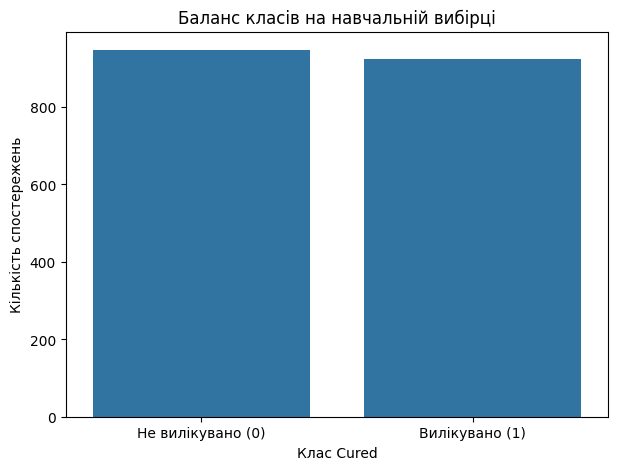

In [9]:
plt.figure(figsize=(7, 5))

sns.countplot(x=y_train)

plt.title("Баланс класів на навчальній вибірці")
plt.xlabel("Клас Cured")
plt.ylabel("Кількість спостережень")
plt.xticks([0, 1], ["Не вилікувано (0)", "Вилікувано (1)"])

plt.show()

**Висновок:**  
Було досліджено баланс класів цільової змінної Cured
на навчальній вибірці. За допомогою підрахунку кількості
спостережень та стовпчикової діаграми визначено
співвідношення між класами 0 та 1.

Баланс класів необхідно враховувати, оскільки значна
перевага одного класу може впливати на якість класифікації.

### 6. Дослідження викидів на навчальних даних

Побудуйте діаграми розмаху для ознак `X_train`. За правилом **1,5 IQR** знайдіть кількість потенційних викидів у кожній ознаці.

На основному етапі **не видаляйте викиди автоматично**. За бажанням пізніше проведіть окремий експеримент із видаленням тільки з навчальної вибірки.

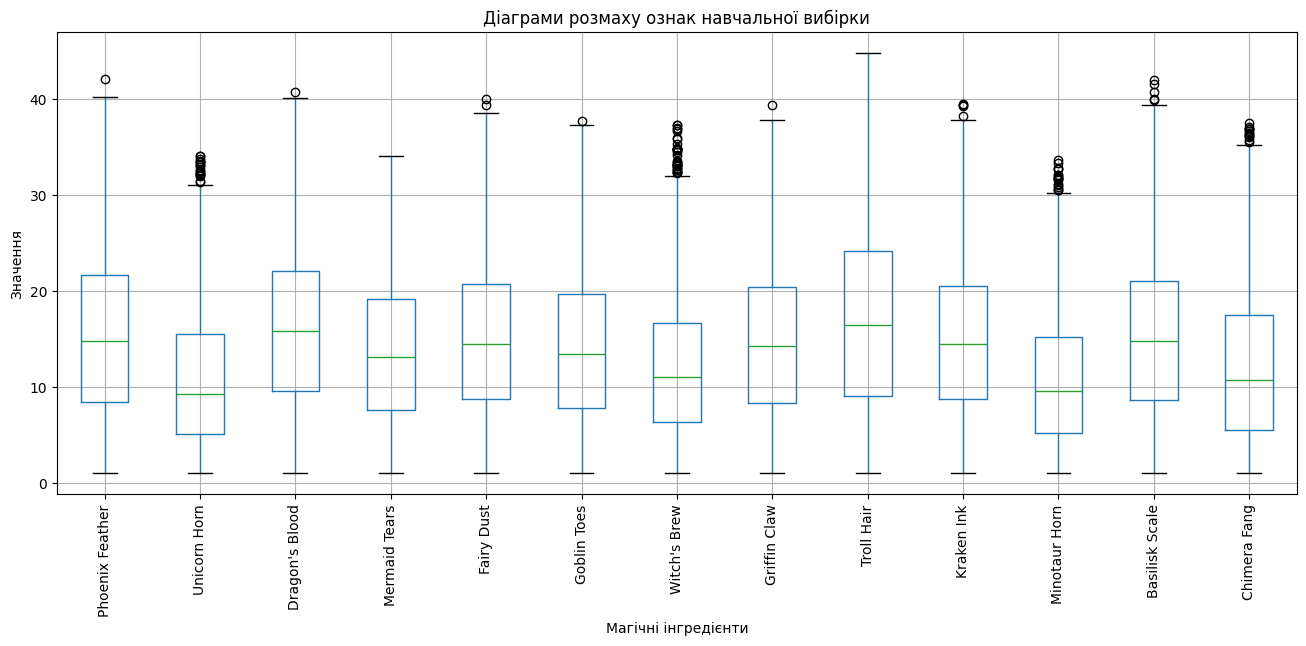

In [10]:
plt.figure(figsize=(16, 6))

X_train.boxplot(rot=90)

plt.title("Діаграми розмаху ознак навчальної вибірки")
plt.xlabel("Магічні інгредієнти")
plt.ylabel("Значення")
plt.grid(True)

plt.show()

In [11]:
# Обчислення першого та третього квартилів
q1 = X_train.quantile(0.25)
q3 = X_train.quantile(0.75)

# Міжквартильний розмах
iqr = q3 - q1

# Межі для визначення викидів
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

# Підрахунок викидів у кожній ознаці
outliers = ((X_train < lower_bound) | (X_train > upper_bound)).sum()

# Сортування за спаданням
outliers = outliers.sort_values(ascending=False)

print("Кількість потенційних викидів у кожній ознаці:")
display(outliers.to_frame(name="Кількість викидів"))

Кількість потенційних викидів у кожній ознаці:


,Кількість викидів
Witch's Brew,33
Unicorn Horn,20
Minotaur Horn,18
Chimera Fang,13
Basilisk Scale,5
Kraken Ink,4
Fairy Dust,2
Phoenix Feather,1
Dragon's Blood,1
Griffin Claw,1


**Висновок про викиди:**  
Для дослідження викидів було побудовано діаграми розмаху
та використано правило 1,5 IQR. За допомогою квартилів
визначено межі допустимих значень для кожної ознаки.

Викиди можуть бути як помилками вимірювання, так і
реальними особливостями даних. Тому автоматичне видалення
всіх таких спостережень не виконувалося.

### 7. Кореляційний аналіз на навчальній вибірці

1. Побудуйте кореляційну матрицю ознак **за модулем** (`.abs()`).
2. Відобразіть її у вигляді `heatmap` із **замаскованим верхнім трикутником** (`np.triu`).
3. Окремо знайдіть кореляцію ознак із цільовою змінною `Cured` **тільки для навчальної вибірки**.

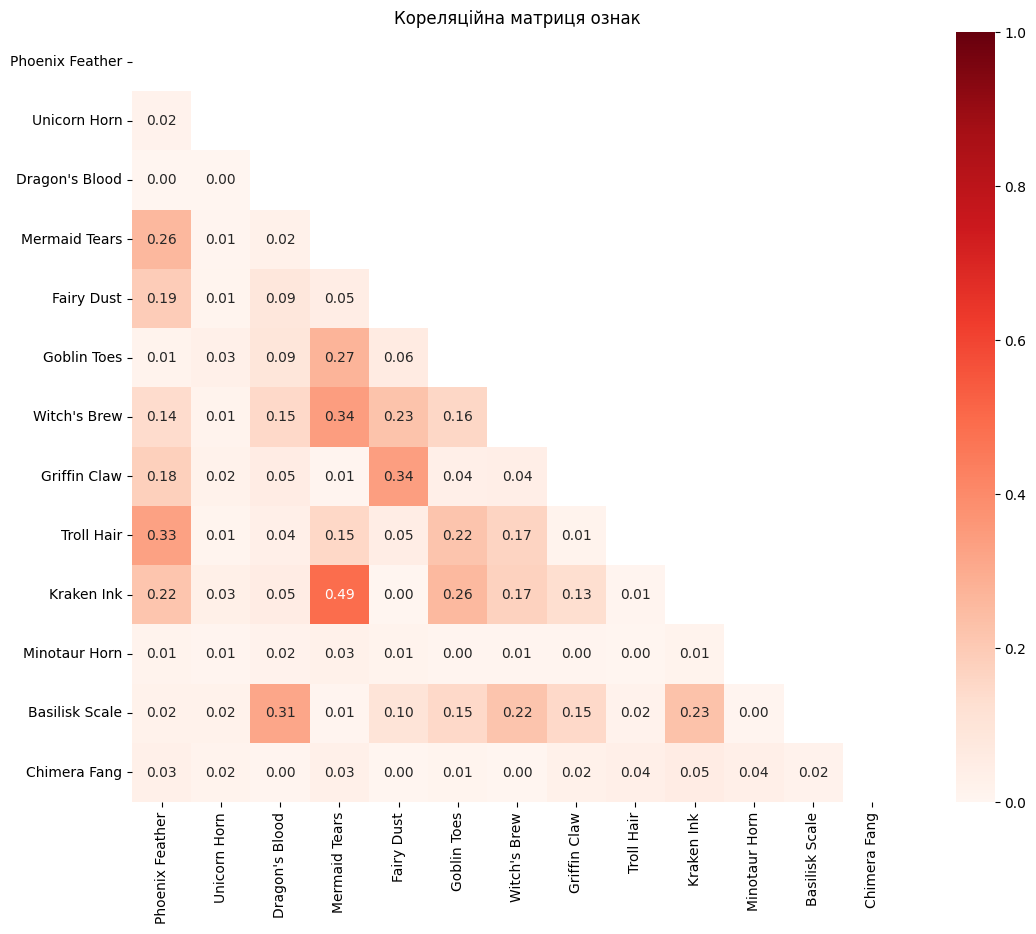

In [12]:
# Обчислення абсолютних значень кореляції
mtx = X_train.corr().abs()

# Маска верхнього трикутника
mask = np.triu(np.ones_like(mtx, dtype=bool))

# Побудова теплової карти
plt.figure(figsize=(14, 10))

sns.heatmap(
    mtx,
    mask=mask,
    annot=True,
    cmap="Reds",
    vmin=0,
    vmax=1,
    fmt=".2f",
    square=True
)

plt.title("Кореляційна матриця ознак")
plt.show()

In [13]:
# Об'єднання ознак та цільової змінної
corr_target = pd.concat([X_train, y_train], axis=1).corr()

# Кореляція з Cured
cured_corr = corr_target["Cured"].drop("Cured")

# Сортування за абсолютним значенням
cured_corr = cured_corr.reindex(
    cured_corr.abs().sort_values(ascending=False).index
)

print("Кореляція ознак із Cured:")
display(cured_corr.to_frame(name="Кореляція"))

Кореляція ознак із Cured:


,Кореляція
Troll Hair,0.488783
Witch's Brew,0.246989
Goblin Toes,0.052573
Chimera Fang,0.047292
Basilisk Scale,-0.042277
Kraken Ink,-0.026598
Minotaur Horn,0.021922
Phoenix Feather,0.020527
Fairy Dust,0.014223
Dragon's Blood,0.010119


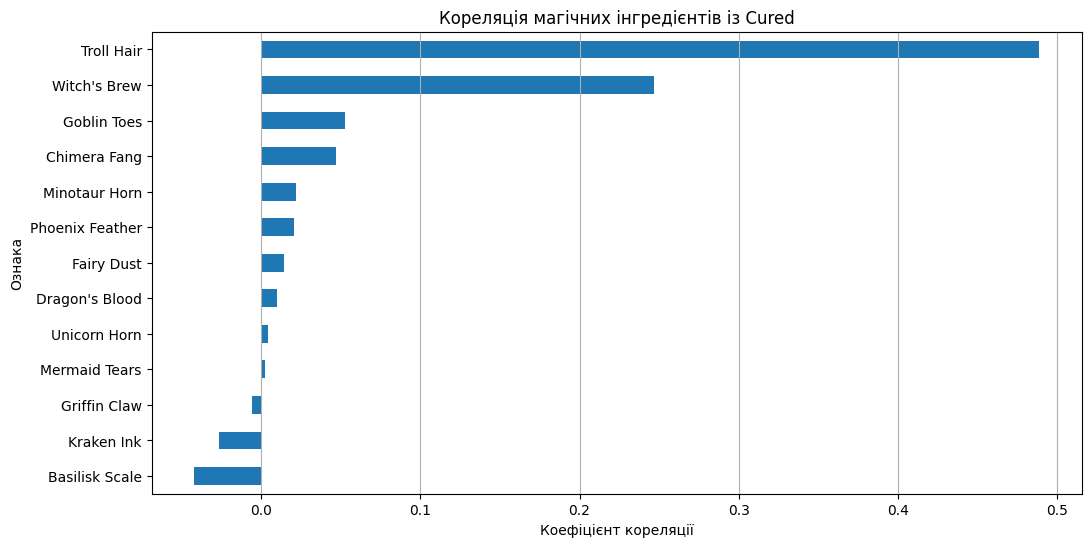

In [14]:
plt.figure(figsize=(12, 6))

cured_corr.sort_values().plot(kind="barh")

plt.title("Кореляція магічних інгредієнтів із Cured")
plt.xlabel("Коефіцієнт кореляції")
plt.ylabel("Ознака")
plt.grid(axis="x")

plt.show()

**Висновок про кореляції:**  
Під час кореляційного аналізу було досліджено взаємозв'язок
між ознаками та їхній зв'язок із цільовою змінною Cured.
Для ознак побудовано кореляційну матрицю за абсолютними
значеннями коефіцієнтів кореляції.

Також визначено ознаки, які мають найсильніший позитивний
або негативний зв'язок із результатом лікування.

### 8. Стандартизація ознак

Скористайтеся `StandardScaler`. Для `X_train` — `fit_transform()`, для `X_test` — тільки `transform()`.

In [15]:
# Створення об'єкта стандартизації
scaler = StandardScaler()

# Навчання стандартизатора тільки на навчальних даних
X_train_scaled = scaler.fit_transform(X_train)

# Перетворення тестових даних
X_test_scaled = scaler.transform(X_test)

print("Розмір стандартизованої навчальної вибірки:",
      X_train_scaled.shape)

print("Розмір стандартизованої тестової вибірки:",
      X_test_scaled.shape)

print("\nСереднє значення стандартизованих ознак:")
print(np.round(X_train_scaled.mean(axis=0), 4))

print("\nСтандартне відхилення:")
print(np.round(X_train_scaled.std(axis=0), 4))

Розмір стандартизованої навчальної вибірки: (1870, 13)
Розмір стандартизованої тестової вибірки: (468, 13)

Середнє значення стандартизованих ознак:
[ 0.  0.  0. -0. -0.  0.  0. -0.  0.  0.  0.  0. -0.]

Стандартне відхилення:
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


### 9. Логістична регресія

Навчіть `LogisticRegression` на стандартизованих навчальних даних. Оцініть модель на тестовій вибірці: **Accuracy**, `classification_report`.

In [16]:
# Створення моделі
model = LogisticRegression(random_state=42)

# Навчання
model.fit(X_train_scaled, y_train)

# Прогнозування
y_pred = model.predict(X_test_scaled)

# Оцінювання точності
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy логістичної регресії:", accuracy)

# Детальний звіт
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Accuracy логістичної регресії: 0.8931623931623932

Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.90      0.89       231
           1       0.90      0.89      0.89       237

    accuracy                           0.89       468
   macro avg       0.89      0.89      0.89       468
weighted avg       0.89      0.89      0.89       468



### 10. Матриця помилок і приклади прогнозів

Побудуйте `confusion_matrix(y_test, y_pred)` та **теплову карту** (`sns.heatmap` із `annot=True`, `fmt='d'`). Порівняйте справжні й передбачені класи для **10 випадкових** тестових спостережень.

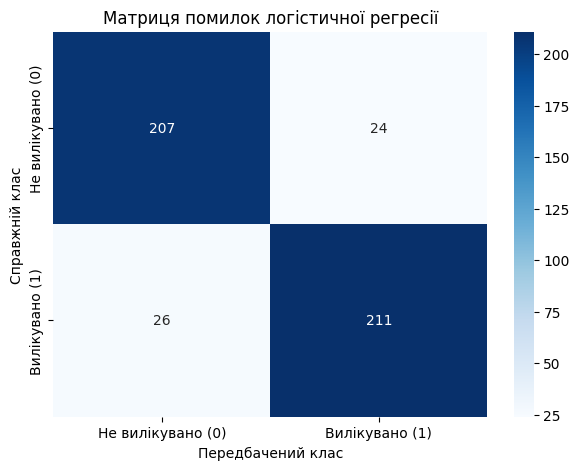

In [17]:
# Обчислення матриці помилок
conf = confusion_matrix(y_test, y_pred)

# Побудова теплової карти
plt.figure(figsize=(7, 5))

sns.heatmap(
    conf,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Не вилікувано (0)", "Вилікувано (1)"],
    yticklabels=["Не вилікувано (0)", "Вилікувано (1)"]
)

plt.title("Матриця помилок логістичної регресії")
plt.xlabel("Передбачений клас")
plt.ylabel("Справжній клас")

plt.show()

In [18]:
# Створення таблиці справжніх і передбачених класів
results = pd.DataFrame({
    "Справжній клас": y_test,
    "Передбачений клас": y_pred
})

# Випадковий вибір 10 спостережень
display(results.sample(10, random_state=42))

,Справжній клас,Передбачений клас
1133,0,1
1018,0,0
1761,1,0
564,1,1
1467,1,1
1927,0,0
408,1,1
2094,1,1
532,0,0
291,1,1


**Висновок щодо якості логістичної регресії:**  
За допомогою матриці помилок було досліджено правильні
та неправильні класифікації моделі.

Окремо порівняно справжні й передбачені значення
для десяти випадкових тестових спостережень.

Accuracy не завжди достатньо для повного оцінювання,
тому додатково враховувалися Precision, Recall та F1-score.

### 11. Підбір гіперпараметрів

Задайте набори параметрів для `LogisticRegression`. Проведіть підбір через **GridSearchCV** та **RandomizedSearchCV** із `cv=3`, `scoring='accuracy'`. Порівняйте найкращі параметри та отриману якість.

*Підказка:* дослідіть параметри `C`, `solver`, `max_iter`. Підбір виконуйте на **навчальній** вибірці.

In [19]:
# Сітка параметрів
param_grid = {
    "C": [0.01, 0.1, 1, 10, 100],
    "solver": ["lbfgs", "liblinear"],
    "max_iter": [100, 300, 500, 1000]
}

# Створення пошуку
grid_search = GridSearchCV(
    LogisticRegression(random_state=42),
    param_grid,
    cv=3,
    scoring="accuracy",
    n_jobs=-1
)

# Навчання
grid_search.fit(X_train_scaled, y_train)

print("Найкращі параметри GridSearchCV:")
print(grid_search.best_params_)

print("\nНайкраща середня CV Accuracy:")
print(grid_search.best_score_)

Найкращі параметри GridSearchCV:
{'C': 10, 'max_iter': 100, 'solver': 'lbfgs'}

Найкраща середня CV Accuracy:
0.8673927508197171


In [20]:
# Набір параметрів
param_dist = {
    "C": [0.001, 0.01, 0.1, 1, 10, 100, 1000],
    "solver": ["lbfgs", "liblinear"],
    "max_iter": [100, 200, 300, 500, 1000, 1500]
}

# Створення випадкового пошуку
random_search = RandomizedSearchCV(
    LogisticRegression(random_state=42),
    param_distributions=param_dist,
    n_iter=20,
    cv=3,
    scoring="accuracy",
    random_state=42,
    n_jobs=-1
)

# Навчання
random_search.fit(X_train_scaled, y_train)

print("Найкращі параметри RandomizedSearchCV:")
print(random_search.best_params_)

print("\nНайкраща середня CV Accuracy:")
print(random_search.best_score_)

Найкращі параметри RandomizedSearchCV:
{'solver': 'liblinear', 'max_iter': 100, 'C': 1000}

Найкраща середня CV Accuracy:
0.8673927508197171


In [21]:
# Вибір найкращої моделі за результатами крос-валідації
if grid_search.best_score_ >= random_search.best_score_:
    best_model = grid_search.best_estimator_
    best_method = "GridSearchCV"
else:
    best_model = random_search.best_estimator_
    best_method = "RandomizedSearchCV"

# Прогнозування
y_pred_best = best_model.predict(X_test_scaled)

# Оцінювання
best_accuracy = accuracy_score(y_test, y_pred_best)

print("Обраний метод:", best_method)
print("Найкращі параметри:", best_model.get_params())
print("Accuracy найкращої моделі:", best_accuracy)

print("\nClassification Report:")
print(classification_report(y_test, y_pred_best))

Обраний метод: GridSearchCV
Найкращі параметри: {'C': 10, 'class_weight': None, 'dual': False, 'fit_intercept': True, 'intercept_scaling': 1, 'l1_ratio': None, 'max_iter': 100, 'multi_class': 'deprecated', 'n_jobs': None, 'penalty': 'l2', 'random_state': 42, 'solver': 'lbfgs', 'tol': 0.0001, 'verbose': 0, 'warm_start': False}
Accuracy найкращої моделі: 0.8931623931623932

Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.90      0.89       231
           1       0.90      0.89      0.89       237

    accuracy                           0.89       468
   macro avg       0.89      0.89      0.89       468
weighted avg       0.89      0.89      0.89       468



**Висновок про підбір параметрів:**  
Для оптимізації логістичної регресії було використано
GridSearchCV та RandomizedSearchCV.

Обидва методи дозволили дослідити різні комбінації
гіперпараметрів C, solver та max_iter.

Найкращу модель було обрано за результатами
крос-валідації на навчальній вибірці та перевірено
на тестових даних.

### 12. Порівняння трьох моделей

Побудуйте також **метод опорних векторів (`SVC`)** і **дерево рішень (`DecisionTreeClassifier`)**. Порівняйте ці дві моделі з логістичною регресією за **Accuracy** та **F1-score** на однаковій тестовій вибірці. Оберіть найкращу модель і поясніть вибір.

In [22]:
# Створення моделей
models = {
    "Logistic Regression": best_model,
    "SVM": SVC(),
    "Decision Tree": DecisionTreeClassifier(random_state=42)
}

# Словник для збереження результатів
model_results = []

# Навчання та оцінювання кожної моделі
for name, clf in models.items():

    clf.fit(X_train_scaled, y_train)

    predictions = clf.predict(X_test_scaled)

    accuracy = accuracy_score(y_test, predictions)
    f1 = f1_score(y_test, predictions)

    model_results.append({
        "Модель": name,
        "Accuracy": accuracy,
        "F1-score": f1
    })

# Таблиця результатів
comparison = pd.DataFrame(model_results)

comparison = comparison.sort_values(
    by="F1-score",
    ascending=False
)

display(comparison)

,Модель,Accuracy,F1-score
1,SVM,0.959402,0.960000
0,Logistic Regression,0.893162,0.894068
2,Decision Tree,0.865385,0.865672


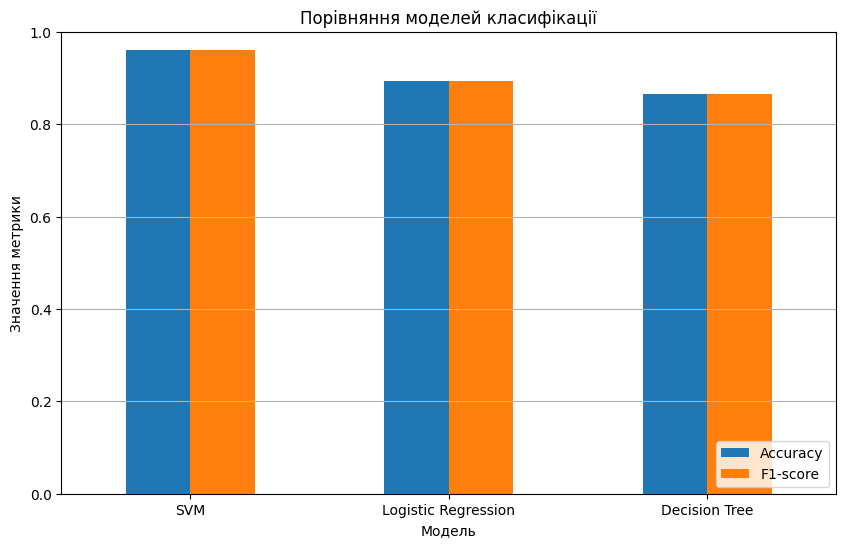

In [23]:
comparison_plot = comparison.set_index("Модель")

comparison_plot.plot(
    kind="bar",
    figsize=(10, 6),
    ylim=(0, 1),
    rot=0
)

plt.title("Порівняння моделей класифікації")
plt.ylabel("Значення метрики")
plt.xlabel("Модель")
plt.grid(axis="y")
plt.legend(loc="lower right")

plt.show()

In [24]:
best_row = comparison.iloc[0]

print("Найкраща модель:", best_row["Модель"])
print("Accuracy:", round(best_row["Accuracy"], 4))
print("F1-score:", round(best_row["F1-score"], 4))

Найкраща модель: SVM
Accuracy: 0.9594
F1-score: 0.96


### 13. Висновки до лабораторної роботи

## Висновки до лабораторної роботи № 7

Під час виконання лабораторної роботи було досліджено методи бінарної класифікації на прикладі датасету «Cure the Princess». Було побудовано модель логістичної регресії, виконано підбір її гіперпараметрів та проведено порівняння з методом опорних векторів і деревом рішень.

Під час первинного аналізу встановлено, що датасет містить 2338 рядків і 14 стовпців. Пропущені значення та дублікати відсутні. Класи цільової змінної `Cured` представлені майже однаковою кількістю спостережень, тому набір даних є збалансованим.

За результатами дослідження викидів найбільшу їх кількість виявлено в ознаках Witch's Brew, Unicorn Horn та Minotaur Horn. Кореляційний аналіз показав, що найсильніший зв'язок із цільовою змінною `Cured` має ознака Troll Hair із коефіцієнтом кореляції 0,4888.

Для побудови логістичної регресії було виконано стандартизацію ознак. Точність базової моделі становила 86,54%. Після підбору гіперпараметрів за допомогою GridSearchCV точність зросла до 89,32%. Найкращими параметрами виявилися C = 10, solver = lbfgs та max_iter = 100.

На завершальному етапі було порівняно три алгоритми класифікації: логістичну регресію, SVM та дерево рішень. Найкращий результат показав метод опорних векторів (SVM), точність якого становила 95,94%, а F1-score — 96,00%. Логістична регресія продемонструвала Accuracy 89,32%, а дерево рішень — 86,54%.

Отже, у результаті лабораторної роботи було засвоєно принципи бінарної класифікації, досліджено вплив стандартизації ознак і підбору гіперпараметрів на якість моделі. Експериментально встановлено, що для досліджуваного датасету найкращим алгоритмом серед трьох перевірених моделей виявився SVM, оскільки він забезпечив найвищі значення Accuracy та F1-score.

In [25]:
# 1. Первинний аналіз
print("1. ПЕРВИННИЙ АНАЛІЗ")
print("Розмір датасету:", df.shape)
print("Кількість пропусків:", df.isnull().sum().sum())
print("Кількість дублікатів:", df.duplicated().sum())

# 2. Баланс класів
print("\n2. БАЛАНС КЛАСІВ")
print(y_train.value_counts())

# 3. Найбільша кількість викидів
print("\n3. НАЙБІЛЬШЕ ВИКИДІВ")
print(outliers.head(5))

# 4. Найсильніші кореляції з Cured
print("\n4. НАЙСИЛЬНІШІ КОРЕЛЯЦІЇ З Cured")
print(cured_corr.head(5))

# 5. Базова логістична регресія
print("\n5. БАЗОВА ЛОГІСТИЧНА РЕГРЕСІЯ")
print("Accuracy:", round(accuracy, 4))

# 6. Оптимізована логістична регресія
print("\n6. ОПТИМІЗОВАНА ЛОГІСТИЧНА РЕГРЕСІЯ")
print("Метод:", best_method)
print("Параметри:", best_model.get_params())
print("Accuracy:", round(best_accuracy, 4))

# 7. Порівняння моделей
print("\n7. ПОРІВНЯННЯ МОДЕЛЕЙ")
display(comparison)

1. ПЕРВИННИЙ АНАЛІЗ
Розмір датасету: (2338, 14)
Кількість пропусків: 0
Кількість дублікатів: 0

2. БАЛАНС КЛАСІВ
Cured
0    946
1    924
Name: count, dtype: int64

3. НАЙБІЛЬШЕ ВИКИДІВ
Witch's Brew      33
Unicorn Horn      20
Minotaur Horn     18
Chimera Fang      13
Basilisk Scale     5
dtype: int64

4. НАЙСИЛЬНІШІ КОРЕЛЯЦІЇ З Cured
Troll Hair        0.488783
Witch's Brew      0.246989
Goblin Toes       0.052573
Chimera Fang      0.047292
Basilisk Scale   -0.042277
Name: Cured, dtype: float64

5. БАЗОВА ЛОГІСТИЧНА РЕГРЕСІЯ
Accuracy: 0.8654

6. ОПТИМІЗОВАНА ЛОГІСТИЧНА РЕГРЕСІЯ
Метод: GridSearchCV
Параметри: {'C': 10, 'class_weight': None, 'dual': False, 'fit_intercept': True, 'intercept_scaling': 1, 'l1_ratio': None, 'max_iter': 100, 'multi_class': 'deprecated', 'n_jobs': None, 'penalty': 'l2', 'random_state': 42, 'solver': 'lbfgs', 'tol': 0.0001, 'verbose': 0, 'warm_start': False}
Accuracy: 0.8932

7. ПОРІВНЯННЯ МОДЕЛЕЙ


,Модель,Accuracy,F1-score
1,SVM,0.959402,0.960000
0,Logistic Regression,0.893162,0.894068
2,Decision Tree,0.865385,0.865672


In [26]:
# Визначення найбільш корельованої пари ознак
upper_corr = mtx.where(
    np.triu(np.ones(mtx.shape), k=1).astype(bool)
)

strongest_pair = upper_corr.stack().idxmax()
strongest_value = upper_corr.stack().max()

# Найкраща модель
best_row = comparison.iloc[0]

# Зміна точності після підбору параметрів
accuracy_change = best_accuracy - accuracy

print("=" * 60)
print("ЗАГАЛЬНІ ВИСНОВКИ ДО ЛАБОРАТОРНОЇ РОБОТИ № 7")
print("=" * 60)

print("\n1. Особливості даних:")
print(f"Датасет містить {df.shape[0]} рядків та {df.shape[1]} стовпців.")
print(f"Кількість пропусків: {df.isnull().sum().sum()}.")
print(f"Кількість дублікатів: {df.duplicated().sum()}.")

print("\n2. Викиди та кореляції:")
print("Ознаки з найбільшою кількістю викидів:")
print(outliers.head(3))
print(f"Найбільш корельована пара: {strongest_pair}.")
print(f"Абсолютна кореляція: {strongest_value:.4f}.")
print("Найсильніший зв'язок із Cured:")
print(cured_corr.head(3))

print("\n3. Базова логістична регресія:")
print(f"Accuracy = {accuracy:.4f}")

print("\n4. Підбір гіперпараметрів:")
print(f"Метод: {best_method}")
print(f"Параметри: {best_model.get_params()}")
print(f"Accuracy після оптимізації: {best_accuracy:.4f}")
print(f"Зміна Accuracy: {accuracy_change:+.4f}")

if accuracy_change > 0:
    print("Точність моделі покращилася.")
elif accuracy_change < 0:
    print("Точність моделі зменшилася.")
else:
    print("Точність моделі не змінилася.")

print("\n5. Порівняння трьох моделей:")
print(f"Найкраща модель: {best_row['Модель']}")
print(f"Accuracy: {best_row['Accuracy']:.4f}")
print(f"F1-score: {best_row['F1-score']:.4f}")

print("\nЛабораторну роботу завершено.")

ЗАГАЛЬНІ ВИСНОВКИ ДО ЛАБОРАТОРНОЇ РОБОТИ № 7

1. Особливості даних:
Датасет містить 2338 рядків та 14 стовпців.
Кількість пропусків: 0.
Кількість дублікатів: 0.

2. Викиди та кореляції:
Ознаки з найбільшою кількістю викидів:
Witch's Brew     33
Unicorn Horn     20
Minotaur Horn    18
dtype: int64
Найбільш корельована пара: ('Mermaid Tears', 'Kraken Ink').
Абсолютна кореляція: 0.4907.
Найсильніший зв'язок із Cured:
Troll Hair      0.488783
Witch's Brew    0.246989
Goblin Toes     0.052573
Name: Cured, dtype: float64

3. Базова логістична регресія:
Accuracy = 0.8654

4. Підбір гіперпараметрів:
Метод: GridSearchCV
Параметри: {'C': 10, 'class_weight': None, 'dual': False, 'fit_intercept': True, 'intercept_scaling': 1, 'l1_ratio': None, 'max_iter': 100, 'multi_class': 'deprecated', 'n_jobs': None, 'penalty': 'l2', 'random_state': 42, 'solver': 'lbfgs', 'tol': 0.0001, 'verbose': 0, 'warm_start': False}
Accuracy після оптимізації: 0.8932
Зміна Accuracy: +0.0278
Точність моделі покращилася.

5